#Lab 1.1 - Análise do esforço computacional da busca linear#
Objetivos:
- Correlacionar a organização de dados com os esforços de recuperação/busca
- Ao analisar o esforço computacional entre a busca linear e busca binária

Objetivos secundários:
- Experimentar o uso de práticas para dinâmica das aulas
- Experimentar e aprender Python
- Compreender sobre geração de números aleatórios
- Compreender sobre visualização de gráficos


Atividades / Passos:
- Gerar um vetor com dados aleatórios
- Implementar a busca linear
- Incorporar medições de tempo e instruções (esforço computacional)
- Realizar os experimentos com exemplos de chave
- Montar a lista de experimentos
- Plotar o gráfico para análise

# **Passo 1 : Geração de números aleatórios em uma lista ("vetor")**
- Compreender a geração de números aleatórios, sobretudo o uso do seed (semente)
- Gerar e manipular uma lista com N elementos

In [9]:
# Compreendendo a geração de números aleatórios
# Questão: Qual diferença ao usar o random.seed() dentro ou fora do FOR?
# dentro do for o valor "aleatorio" sempre será o mesmo, ja que dizemos a semente
# Questão: Em duas ou mais execuções os números aleatórios serão diferentes?
# não, por conta de usarmos o seed 

import random
random.seed(0)
for i in range(5):
    print(random.randint(1, 1000000))

885441
885441
885441
885441
885441


In [2]:
# Criando um vetor (lista) com
#     - N elementos (tamanho),
#     - dentro de uma faixa de valores (limite) e
#     - sempre com uma mesma sequência (seed)
# Questão: No Python existe o conceito de vetor? Como ele trata este recurso?
# como listas, não definimos tamanho, seria como uma lista encadeada
import random

def GeradorDados(tamanho, limite, seed):
    dados = []
    random.seed(seed)
    for i in range(tamanho):
        dados.append(random.randint(1, limite))

    return dados


In [3]:
# Gerando e manipulando os dados
# Questão: Se todos os números aleatórios forem gerados dentro do limite, quantos números serão repetidos?
N   = 1000000    # Quantidade de números no vetor
LIM = 1000000   # Limite para geração do número aleatório
S   = 2         # Seed: para manter sempre uma mesma sequência

dados = GeradorDados(N, LIM, S)

print(" Tamanho da lista: " + str(len(dados)))
print(" Lista: ")
print(dados[0:20])


 Tamanho da lista: 1000000
 Lista: 
[905036, 993870, 890299, 59299, 96034, 88995, 378597, 876085, 177298, 771721, 848259, 702264, 895311, 323105, 263805, 635379, 222528, 636278, 37471, 609437]


# **Passo 2 : Criar função de pesquisa linear**
- Criar a função
- Recuperar um resultado com uma lista que servirá posteriormente para análises da busca

In [4]:
# Questão: O que aconteceria se não houvesse a condição "and (not (Achou))"?
#          ele pecorreria a lista toda
#          Este algoritmo vale caso existam chaves repetidas e se queira recuperar
#          todas as posições delas?
#          não
def PesquisaLinear1(lista, chave):

  achou   = False
  pos     = -1
  tam     = len(lista)
  i       = 0
  while (i < tam ) and (not(achou)):
      if (lista[i] == chave):
        achou = True
        pos = i
      i+=1

  resultado = [chave, achou, pos, 0, 0]

  return resultado

In [5]:
# Lembre-se que a variável dados devem ter sido gerados nos passos anteriores.
posicao = 892             # Posição à experimentar
chave   = dados[posicao]  # Chave na posição do vetor
print(" Valor e posição: " + str(chave) + " - " + str(posicao))

# Realizando a busca
result  = PesquisaLinear1(dados, chave)
print(result)

 Valor e posição: 944453 - 892
[944453, True, 892, 0, 0]


# **Passo 4 : Medir o esforço computacional da função**
- O esforço computacional pode ser medido por tempo ou contando o número de instruções
- Mais a frente, ao revisarmos Análise de Complexidade de Algoritmos, discutiremos mais a respeito.

- A fazer:Acrescentar dados de tempo de execução e número de instruções no resultado

In [6]:
# Questão: O que você acha que terá comportamento mais previsível, tempo de
#          execução ou número de instruções?
#           numero de instruções
import time

# instrs é uma variável que vai contar quantas "instruções"
# t é uma variável que vai recuperar o tempo de execução
def PesquisaLinear2(lista, chave):

  instrs = 4            # Cada instrução neste bloco de abaixo
  t      = time.time()  # recuperando instante atual

  achou = False
  pos = -1
  tam = len(lista)
  i = 0

  while (i < tam ) and (not(achou)):
      if (lista[i] == chave):
        achou = True
        pos = i
        instrs+=2      # 2 instruções acima
      i+=1
      instrs+=4        # While, IF e increm i

  t = time.time() - t      # diferença em relação ao instante
  resultado = [chave, achou, pos, t, instrs]

  return resultado

In [7]:
posicao = 100000        # Posição à experimentar
chave   = dados[posicao]  # Chave na posição do vetor
print(" Valor e posição: " + str(chave) + " - " + str(posicao))

# Realizando a busca
result  = PesquisaLinear2(dados, chave)
print(result)

 Valor e posição: 807285 - 100000
[807285, True, 100000, 0.02500462532043457, 400010]


# **Passo 5 : Realizando os experimentos**
- Experimente a função para vários casos, para o experimento cada caso é uma posição do elemento no vetor

- Faça o experimento para os casos referentes ao seu grupo. Para cada caso, copie e cole o resultado na lista de experimentos abaixo (ela servirá para geração de gráfico).
- Veja lista de casos (posição) conforme grupo:
- Grupo 1: 599160, 34168, 449723, 506003, 606173, 15553, 216110, 485051, 852830, 515162, 863596, 291002, 685216, 849996, 168013
-------
- Grupo 2: 474355, 907797, 586964, 898486, 969106, 819167, 488270, 473781, 532511, 896581, 615918, 199127, 193631, 842951, 536776
-----------
- Grupo 3: 497624, 282062, 689410, 554834, 698783, 366777, 149528, 400180, 11388, 392959, 505979, 287361, 674663, 849712, 482574
-----------
- Grupo 4: 271591, 304882, 718546, 953722, 717312, 840963, 890594, 933231, 194746, 683682, 241759, 698547, 154309, 911455, 236101
-----------
- Grupo 5: 112018, 645796, 736715, 791891, 683716, 552717, 986031, 258931, 284285, 770842, 268201, 305153, 769718, 76154, 690435
-----------
- Grupo 6: 219132, 12221, 546641, 771744, 37934, 165689, 957365, 250558, 17701, 57618, 922214, 843972, 714448, 154402, 898989
-----------
- Grupo 7: 379085, 492016, 503821, 298775, 437207, 237655, 468462, 6138, 429409, 895628, 689655, 745540, 271430, 249413, 665842
-----------
- Grupo 8: 547340, 434287, 845877, 318163, 383385, 303695, 183174, 803322, 739396, 738429, 566426, 693511, 291795, 115514, 962062
-----------
- Grupo 9: 190070, 128782, 693561, 470628, 350812, 251131, 207555, 998153, 513295, 658703, 518033, 191863, 503078, 309826, 480596
-----------
- Grupo 10: 710018, 45355, 823040, 938907, 545749, 126552, 536338, 209189, 412652, 364033, 554906, 303422, 613109, 155462, 623903
-----------
- Grupo 11: 949633, 757911, 719590, 824893, 803744, 922709, 948559, 158551, 272449, 706751, 666607, 890598, 948905, 106448, 914495
-----------
- Grupo 12: 172963, 438299, 723274, 438337, 665846, 294920, 502374, 884242, 226508, 831137, 497704, 847097, 537350, 192499, 529620
-----------
- Grupo 13: 951440, 147188, 254403, 24764, 642869, 468854, 193204, 736053, 126450, 775520, 683065, 921306, 362435, 831077, 932762
-----------






In [8]:


g10 = [710018, 45355, 823040, 938907, 545749, 126552, 536338, 209189, 412652, 364033, 554906, 303422, 613109, 155462, 623903]

for g in g10:
    chave = dados[g]
    result = PesquisaLinear2(dados, chave)
    #print(f"pos: {g}, val: {dados[g]}")
    print(result, ",")


[333709, True, 710018, 0.16203665733337402, 2840082] ,
[841920, True, 45355, 0.011003732681274414, 181430] ,
[786351, True, 823040, 0.19704079627990723, 3292170] ,
[58852, True, 43573, 0.009001493453979492, 174302] ,
[143820, True, 203951, 0.045011043548583984, 815814] ,
[203073, True, 126552, 0.028003692626953125, 506218] ,
[554616, True, 437174, 0.04300880432128906, 1748706] ,
[827577, True, 209189, 0.02100539207458496, 836766] ,
[775197, True, 412652, 0.03900909423828125, 1650618] ,
[966800, True, 364033, 0.038007259368896484, 1456142] ,
[867285, True, 554906, 0.059015512466430664, 2219634] ,
[84696, True, 303422, 0.030005216598510742, 1213698] ,
[783063, True, 579286, 0.057012319564819336, 2317154] ,
[36771, True, 155462, 0.0180051326751709, 621858] ,
[546379, True, 623903, 0.07101607322692871, 2495622] ,


In [11]:
# Os resultados da execução acima devem ser copiados para esta lista
lstresults = [[333709, True, 710018, 0.16203665733337402, 2840082] ,
[841920, True, 45355, 0.011003732681274414, 181430] ,
[786351, True, 823040, 0.19704079627990723, 3292170] ,
[58852, True, 43573, 0.009001493453979492, 174302] ,
[143820, True, 203951, 0.045011043548583984, 815814] ,
[203073, True, 126552, 0.028003692626953125, 506218] ,
[554616, True, 437174, 0.04300880432128906, 1748706] ,
[827577, True, 209189, 0.02100539207458496, 836766] ,
[775197, True, 412652, 0.03900909423828125, 1650618] ,
[966800, True, 364033, 0.038007259368896484, 1456142] ,
[867285, True, 554906, 0.059015512466430664, 2219634] ,
[84696, True, 303422, 0.030005216598510742, 1213698] ,
[783063, True, 579286, 0.057012319564819336, 2317154] ,
[36771, True, 155462, 0.0180051326751709, 621858] ,
[546379, True, 623903, 0.07101607322692871, 2495622]]

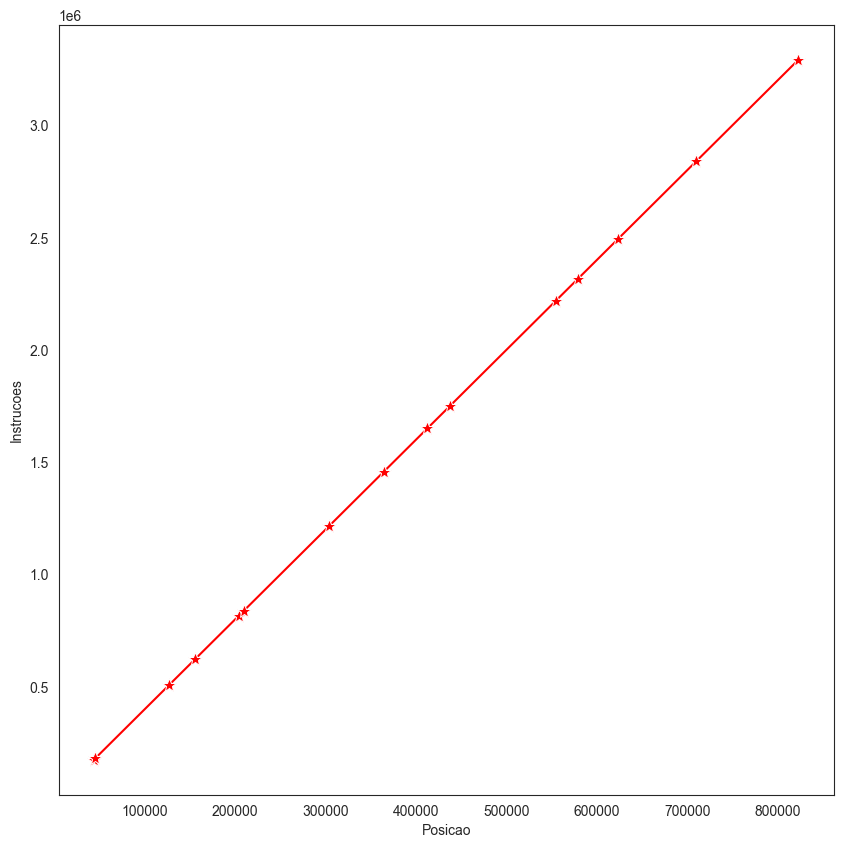

In [14]:
# Questão: Verifique de o Pandas e o Dataframe são muito usados em ciência de dados?
#          Imagine como seria um gráfico (Tempo vs Posição da Chave) e (Número de Instruções vs Posição)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# Analisando graficamente

# Gerando um Dataframe, isso ajudará na produção dos gráficos
# Veremos mais sobre Dataframes e Gráficos em próximos capítulos
df = pd.DataFrame(lstresults, columns =['Chave', 'Existe', 'Posicao', 'Tempo', 'Instrucoes'])

# Criando o ambiente do gráfico
sns.set_style("white")
plt.figure(figsize=(10, 10))

# Gráfico de Dispersão
graf_linha = sns.lineplot(data = df, x="Posicao", y="Instrucoes",
                          color="red", marker="*", markersize=10, markers="True")
plt.show()


# **Conclusão:**
- Cuidado ao realizar as tarefas, mergulhar no passo a passo e não refletir sobre o que está sendo feito e deseja-se analiar.
- 1) Para um vetor de 1000 números desorganizados, qual o esforço para "encontrar" (perceber que ela não existe) uma chave que não existe no vetor?
- 2) E qual o melhor caso, situação em que haveria o menor número de instruções? Onde ele estaria posicionado no gráfico?
- 3) E qual o pior caso e onde estaria no gráfico?
- 4) Qual o formato (grau) da função de complexidade do algoritmo? Qual parâmetros no gráfico que caracterizam esta função?
